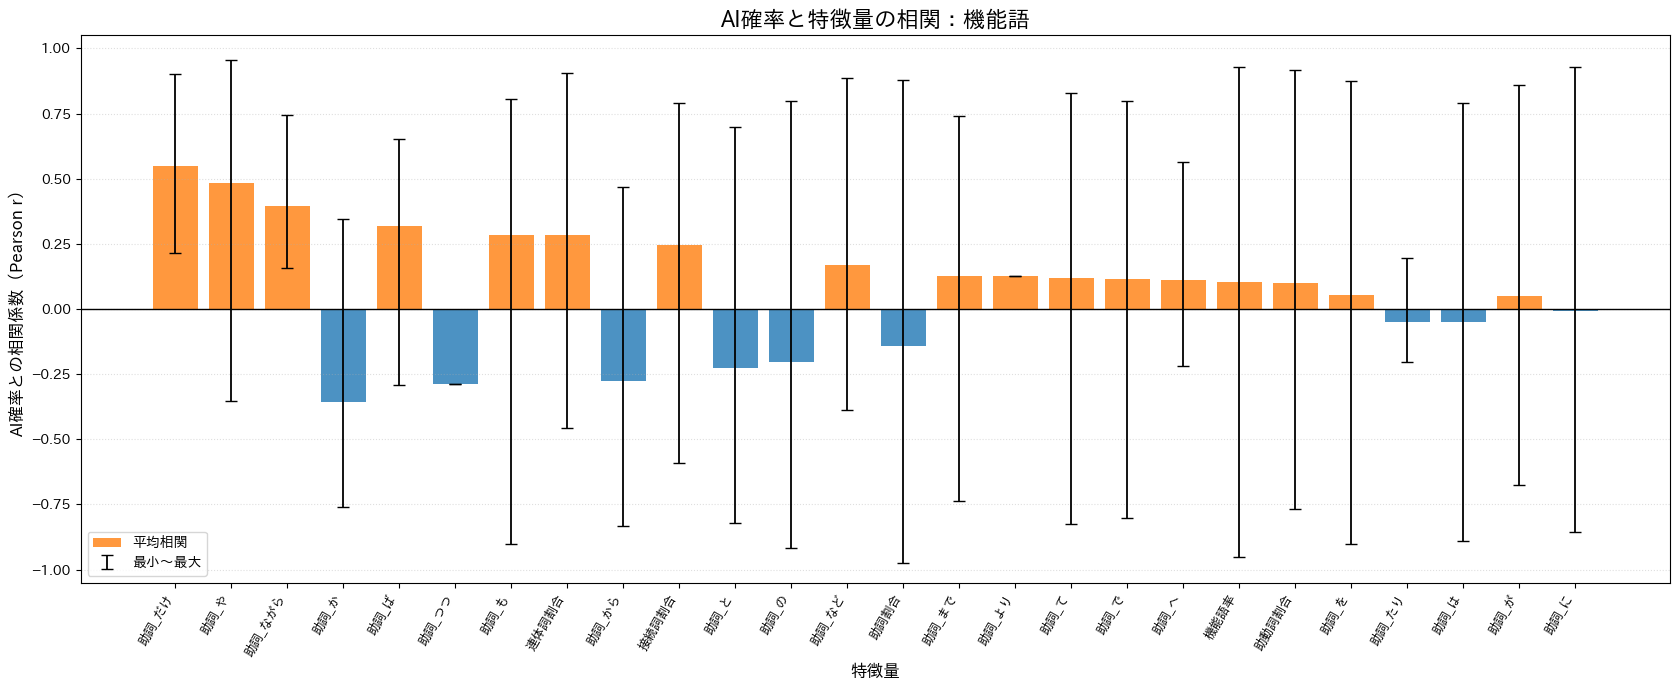

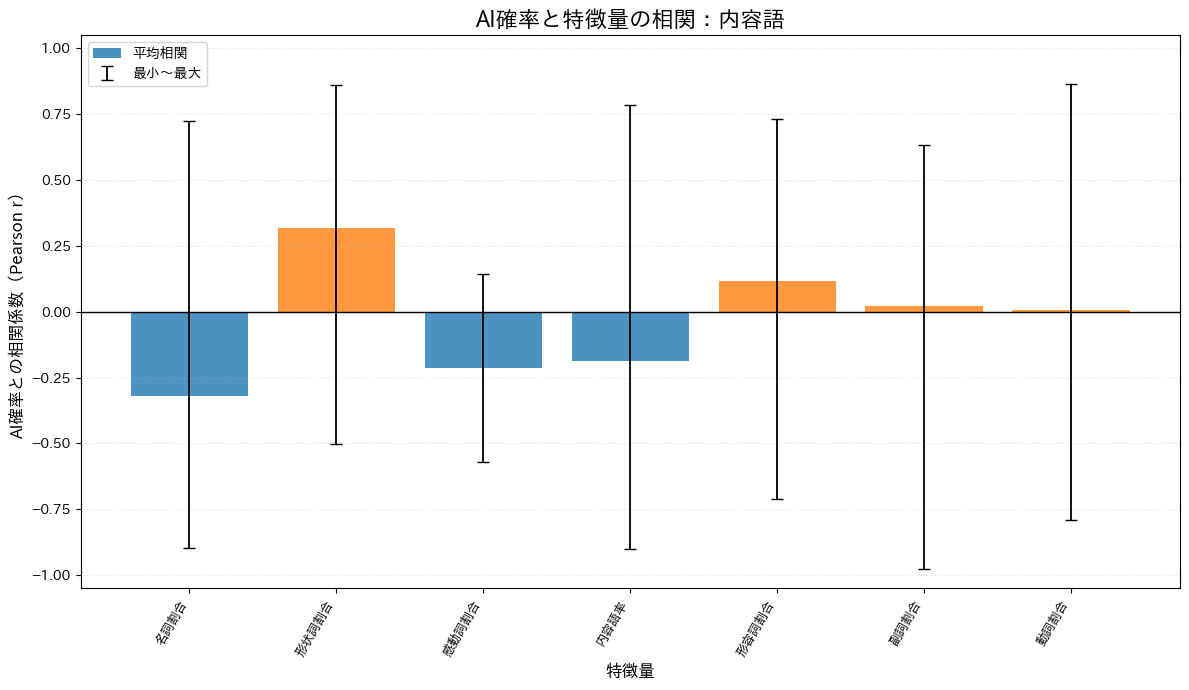

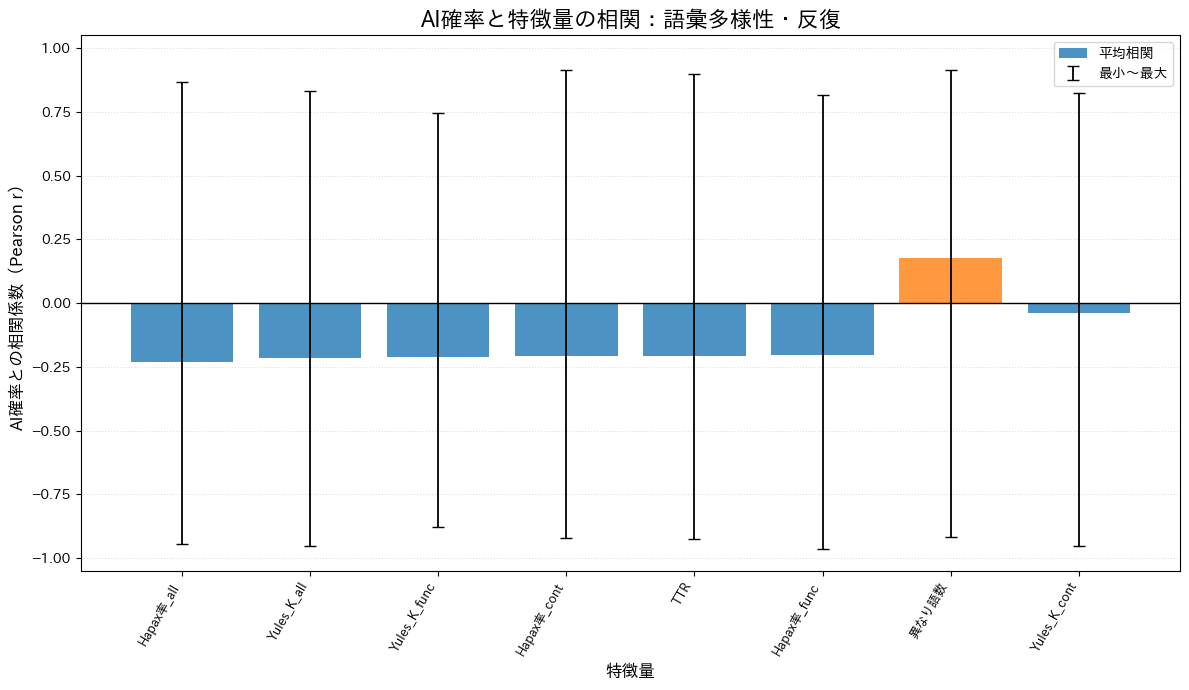

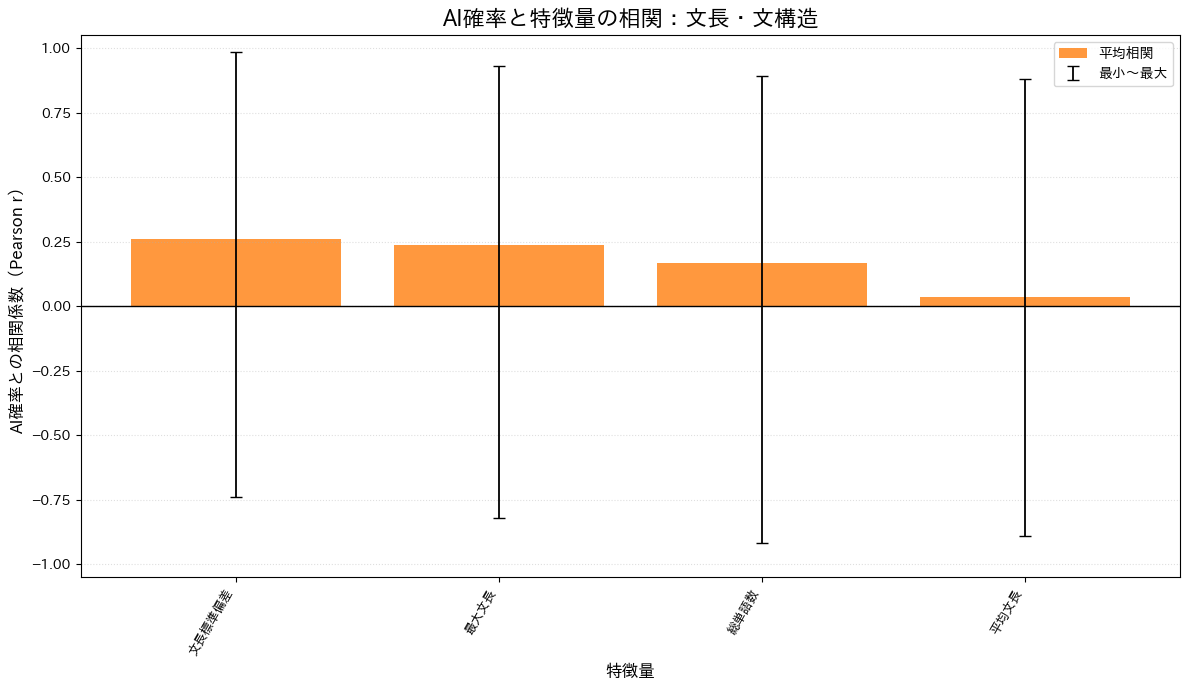

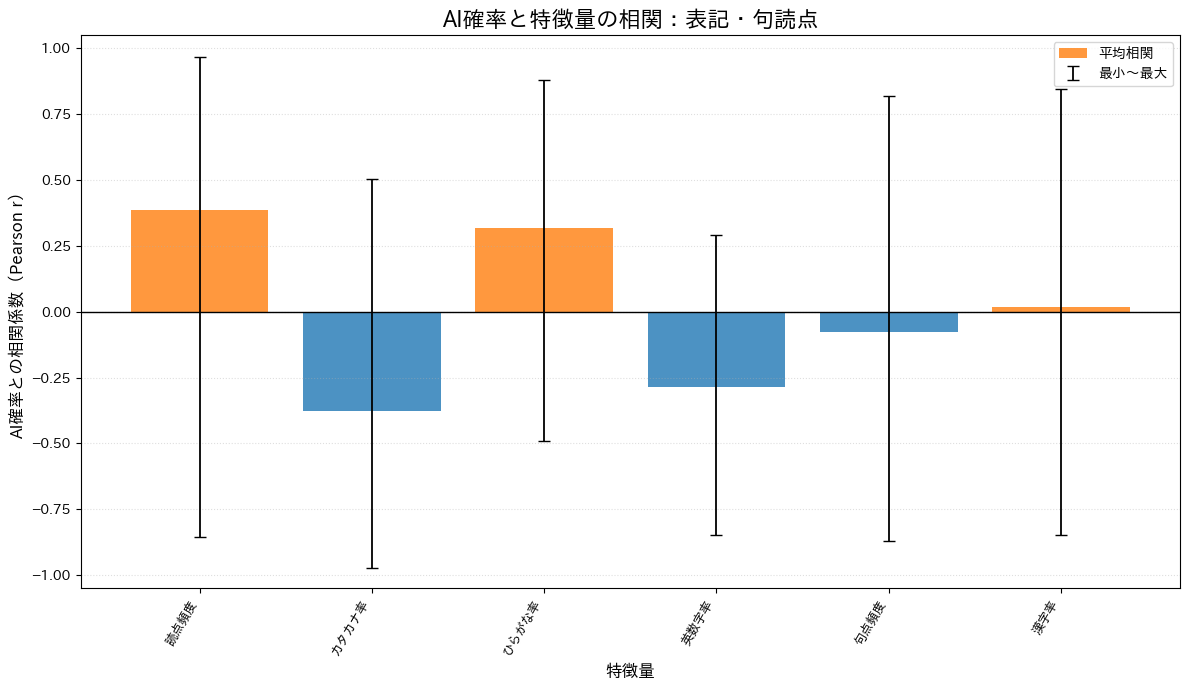

グラフ・集計結果の保存先: /workspace/研究/one-sentence/AI確信度/LR_AI確率_特徴量相関グラフ

集計結果の例:


,グループ,特徴量,平均相関,最小相関,最大相関,文章数
16,機能語,助詞_だけ,0.549569,0.214997,0.902481,9
30,機能語,助詞_や,0.481750,-0.352260,0.957124,19
21,機能語,助詞_ながら,0.394127,0.157317,0.743241,5
42,表記・句読点,読点頻度,0.385830,-0.857439,0.969446,20
38,表記・句読点,カタカナ率,-0.377709,-0.972943,0.504949,16
12,機能語,助詞_か,-0.358429,-0.761409,0.345717,5
3,内容語,名詞割合,-0.321702,-0.897618,0.726113,20
26,機能語,助詞_ば,0.320257,-0.293254,0.652422,4
5,内容語,形状詞割合,0.319670,-0.503260,0.862843,19
37,表記・句読点,ひらがな率,0.319041,-0.489294,0.881421,20


In [4]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

# ==========================================
# 1. データ読み込み
# ==========================================
current_dir = os.getcwd()
csv_path = os.path.join(
    current_dir,
    "LR_predict_proba_cumulative_features_merged.csv"
)
df = pd.read_csv(csv_path)

# ==========================================
# 2. 特徴量の5グループ
# ==========================================
feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合",
        "連体詞割合", "接続詞割合",
        "助詞_と", "助詞_は", "助詞_の", "助詞_で",
        "助詞_て", "助詞_に", "助詞_や", "助詞_を",
        "助詞_ば", "助詞_が", "助詞_も", "助詞_つつ",
        "助詞_から", "助詞_など", "助詞_へ", "助詞_まで",
        "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],
    "内容語": [
        "内容語率", "名詞割合", "動詞割合",
        "形容詞割合", "形状詞割合", "副詞割合",
        "感動詞割合"
    ],
    "語彙多様性・反復": [
        "異なり語数", "TTR",
        "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],
    "文長・文構造": [
        "総単語数", "文長標準偏差",
        "最大文長", "平均文長"
    ],
    "表記・句読点": [
        "ひらがな率", "カタカナ率",
        "漢字率", "英数字率",
        "読点頻度", "句点頻度",
        "感嘆符数", "疑問符数"
    ]
}

# ==========================================
# 3. 文章ごとに相関係数を計算
# ==========================================
correlation_rows = []

for doc_id, doc in df.groupby("doc_id"):
    doc = doc.sort_values("sent_order")

    # データ点が少なすぎる場合は除外
    if len(doc) < 3:
        continue

    proba = pd.to_numeric(
        doc["AI確率"], errors="coerce"
    )

    for group_name, features in feature_groups.items():
        for feature in features:
            if feature not in doc.columns:
                continue

            values = pd.to_numeric(
                doc[feature], errors="coerce"
            )

            pair = pd.DataFrame({
                "AI確率": proba,
                "特徴量": values
            }).dropna()

            # 相関係数を計算できる条件を確認
            if (
                len(pair) < 3
                or pair["AI確率"].nunique() < 2
                or pair["特徴量"].nunique() < 2
            ):
                continue

            r = pair["AI確率"].corr(pair["特徴量"])

            if pd.notna(r):
                correlation_rows.append({
                    "doc_id": doc_id,
                    "label": doc["label"].iloc[0],
                    "グループ": group_name,
                    "特徴量": feature,
                    "相関係数": r
                })

df_corr = pd.DataFrame(correlation_rows)

if df_corr.empty:
    raise ValueError(
        "相関係数を計算できませんでした。"
        "AI確率と特徴量の列・値を確認してください。"
    )

# ==========================================
# 4. 文章間の平均・最小・最大
# ==========================================
df_stats = (
    df_corr.groupby(["グループ", "特徴量"])["相関係数"]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
    .rename(columns={
        "mean": "平均相関",
        "min": "最小相関",
        "max": "最大相関",
        "count": "文章数"
    })
)

# ==========================================
# 5. グループ別の棒グラフ
# ==========================================
output_dir = os.path.join(
    current_dir,
    "LR_AI確率_特徴量相関グラフ"
)
os.makedirs(output_dir, exist_ok=True)

for group_name in feature_groups:
    stats = df_stats[
        df_stats["グループ"] == group_name
    ].copy()

    if stats.empty:
        print(f"スキップ: {group_name}（データなし）")
        continue

    # 平均相関の大きい順に並べる
    stats["abs_mean"] = stats["平均相関"].abs()
    stats = stats.sort_values("abs_mean", ascending=False)

    x = np.arange(len(stats))
    mean_values = stats["平均相関"].to_numpy()

    # 平均から最小・最大までのエラーバー
    lower_error = mean_values - stats["最小相関"].to_numpy()
    upper_error = stats["最大相関"].to_numpy() - mean_values

    fig_width = max(12, len(stats) * 0.65)
    fig, ax = plt.subplots(figsize=(fig_width, 7))

    bars = ax.bar(
        x,
        mean_values,
        color=[
            "#ff7f0e" if value >= 0 else "#1f77b4"
            for value in mean_values
        ],
        alpha=0.8,
        label="平均相関"
    )

    ax.errorbar(
        x,
        mean_values,
        yerr=np.vstack([lower_error, upper_error]),
        fmt="none",
        ecolor="black",
        capsize=4,
        linewidth=1.3,
        label="最小〜最大"
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel("AI確率との相関係数（Pearson r）", fontsize=12)
    ax.set_xlabel("特徴量", fontsize=12)
    ax.set_title(
        f"AI確率と特徴量の相関：{group_name}",
        fontsize=16
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        stats["特徴量"],
        rotation=60,
        ha="right",
        fontsize=9
    )

    ax.grid(axis="y", linestyle=":", alpha=0.4)
    ax.legend()
    plt.tight_layout()

    safe_name = group_name.replace("/", "・")
    output_path = os.path.join(
        output_dir,
        f"相関_{safe_name}.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ==========================================
# 6. 集計結果をCSV保存
# ==========================================
stats_path = os.path.join(
    output_dir,
    "特徴量別_相関係数の平均最小最大.csv"
)
df_stats.drop(columns=["abs_mean"], errors="ignore").to_csv(
    stats_path,
    index=False,
    encoding="utf-8-sig"
)

# 文章ごとの相関係数も保存
df_corr.to_csv(
    os.path.join(output_dir, "文章別_相関係数.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("グラフ・集計結果の保存先:", output_dir)
print("\n集計結果の例:")
display(
    df_stats.sort_values(
        "平均相関",
        key=lambda s: s.abs(),
        ascending=False
    ).head(15)
)
